In [15]:
import os
os.chdir("D:/tmp_workplace/dynamic_structure/250331/C_VRV/structure_feature_detection_evaluation/plot_partition_merge")
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
import pandas as pd
from scipy import sparse
import matplotlib.patches as patches
from matplotlib.colors import LinearSegmentedColormap

In [2]:
pairs = set()
with open("28S_rRNA_c.bedpe","r")as f:
    for line in f:
        if "chrom" in line:
            continue
        else:
            sub = line.strip().split()
            left = int(sub[1])
            right = int(sub[4])
            if left < right:
                pairs.add((left,right))

In [7]:
iscore = []
oscore = []
oloc = []

with open("hybrid_score.matrix","r")as f:
    for line in f:
        sub = line.strip().split()
        left = int(sub[2])
        right = int(sub[6])
        score = int(sub[8])

        if (left,right) in pairs:
            iscore.append(score)
        else:
            oscore.append(score)
            oloc.append((left,right))

iscore = np.array(iscore)
oscore = np.array(oscore)

In [4]:
print(len(iscore),len(oscore))
print(np.mean(iscore),np.mean(oscore))
print(np.median(iscore),np.median(oscore))

931 46823
1099766.6433942 1415.5019114537727
5937.0 1086.0


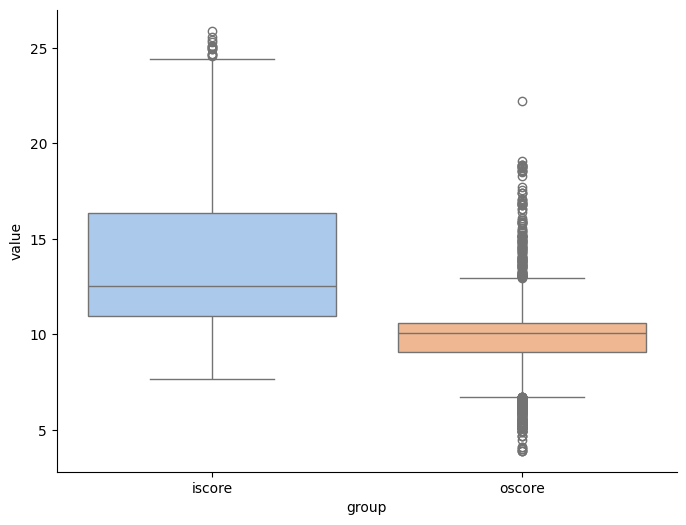

In [7]:
fig, axs = plt.subplots(1, figsize=(8, 6))

all_data = [np.log2(iscore),np.log2(oscore)]

labels = ['iscore','oscore']

df = pd.DataFrame({
    'value': np.concatenate(all_data),
    'group': np.repeat(labels, [len(data) for data in all_data])
})

ax = sns.boxplot(x='group', y='value', data=df, hue='group', legend=False,palette="pastel") #, cut=0 ,showfliers=False

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.savefig("score_of_each_pairs.pdf", format="pdf", bbox_inches="tight")

In [6]:
stat, p_val = mannwhitneyu(iscore, oscore, alternative='two-sided')
print(stat,p_val)
        
effect_r = 1 - (2 * stat) / (len(iscore) * len(oscore))
print(effect_r)

39963588.5 0.0
-0.8335196013104451
